<p><a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a></p>

<p><a href="https://query.farm/vgi/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/vgi-logo.png" alt="VGI" width="112"></a></p>

# [Quantitative Finance Math](https://github.com/vgi-quant)

Black-Scholes option prices and Greeks, bond pricing and yield, and day-count math as SQL functions, backed by QuantLib.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/vgi-quant/blob/main/notebooks/02_clean_quotes_and_yield_shocks.ipynb)

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Example notes](https://github.com/vgi-quant/blob/main/notebooks/README.md)


## What does a bond quote change measure?

A larger face amount does not make a quoted clean price ten times larger. First audit the release’s actual price units, then compare full yield repricing with fixed duration/convexity approximations for three authored bonds. Finally invert each computed clean price back to its input yield.

The worker fixes the schedule start and evaluation date at **2026-06-15**, uses a null calendar with unadjusted dates, Actual/Actual ISDA coupons, and semiannual compounding. Whole-year maturities are 2, 5 and 10 years, with 5% coupons and initial yield. At this issue-date snapshot there is no elapsed coupon accrual; the comparison does not model a later settlement or accrued interest.

In [1]:
YIELD_RANGE_BP = 25  # Symmetric yield change in basis points; experiment: 200

In [2]:
import importlib.metadata as packages
import sys

installed = {d.metadata["Name"]: d.version for d in packages.distributions()}
if installed.get("vgi-example-notebooks") != "0.3.50":
    %pip install -q "git+https://github.com/Query-farm/vgi-example-notebooks@v0.3.50"
    if "vgi_notebooks" in sys.modules:
        raise RuntimeError("Restart the session after updating the example tools, then run all.")

In [3]:
from pathlib import Path

from IPython.display import display
from vgi_notebooks import check_runtime, connect, prepare, prose, theme

check_runtime()
prepare("quant")
import quant_example as example

session = connect(globals())
assert con.execute("SELECT * FROM duckdb_secrets()").fetchall() == []
theme()
assert type(YIELD_RANGE_BP) is int and 5 <= YIELD_RANGE_BP <= 300 and YIELD_RANGE_BP % 5 == 0

### Query the published release

The literal Git-tag command launches the unchanged QuantLib worker in its own environment. These are authored model inputs, not market observations. Python presents returned tables; the analytical transformations stay visible in SQL.

In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'quant' (TYPE vgi, LOCATION 'uvx --python 3.13 --from git+https://github.com/Query-farm/vgi-quant@v0.5.0 vgi-quant-worker');

,Success


### Establish units before multiplying

The catalog prose says a par bond prices near its face value. The actual release calls QuantLib’s clean-price API and returns a **quote per 100 nominal**. Query two face amounts to make the distinction visible. Cash-equivalent clean value is `quote × face / 100`; no transaction or accrued-interest calculation is implied.

In [5]:
%%sql face_quotes <<
SELECT face, quant.main.bond_price(face,0.05,0.05,10,2) AS clean_quote_per_100
FROM (VALUES(100.0::DOUBLE),(1000.0::DOUBLE)) t(face) ORDER BY face;

In [6]:
display(face_quotes)
assert abs(face_quotes.clean_quote_per_100.iloc[0] - face_quotes.clean_quote_per_100.iloc[1]) < 1e-9
prose(
    f"Both face amounts return approximately **{face_quotes.clean_quote_per_100.iloc[0]:.6f} per 100 nominal**. The 1,000-face instrument's clean cash-equivalent value is **{face_quotes.clean_quote_per_100.iloc[1] * 10:.6f} currency units**. The tiny departure from 100 reflects the worker's calendar/day-count construction, not a market discount."
)

,face,clean_quote_per_100
0,100.0,99.99992
1,1000.0,99.99992


Both face amounts return approximately **99.999920 per 100 nominal**. The 1,000-face instrument's clean cash-equivalent value is **999.999202 currency units**. The tiny departure from 100 reflects the worker's calendar/day-count construction, not a market discount.

### Hold initial sensitivities fixed

Duration is modified duration; convexity is the normalized second derivative with respect to the annual decimal yield under the worker’s coupon-frequency compounding. For a yield shift Δy, the first estimate is `−P₀ D Δy`; adding `½ P₀ C Δy²` gives the second-order estimate. A basis point is 0.0001 in annual yield, so the SQL converts units before multiplying.

In [7]:
%%sql
CREATE TABLE bonds AS SELECT years,100.0::DOUBLE AS face,0.05::DOUBLE AS coupon,0.05::DOUBLE AS base_yield
FROM (VALUES(2),(5),(10)) t(years);
CREATE TABLE baseline AS SELECT *,
 quant.main.bond_price(face,coupon,base_yield,years,2) AS base_price,
 quant.main.bond_duration(face,coupon,base_yield,years,2) AS duration,
 quant.main.bond_convexity(face,coupon,base_yield,years,2) AS convexity FROM bonds;

,Count


In [8]:
%%sql baseline_frame <<
SELECT * FROM baseline ORDER BY years;

In [9]:
display(baseline_frame)
prose(
    "These are initial-model sensitivities. Full repricing below changes yield while retaining each instrument's schedule; it is not a forecast of a traded bond's return."
)

,years,face,coupon,base_yield,base_price,duration,convexity
0,2,100.0,0.05,0.05,99.999911,1.882345,4.537071
1,5,100.0,0.05,0.05,99.999987,4.376037,22.612261
2,10,100.0,0.05,0.05,99.999920,7.795503,73.646923


These are initial-model sensitivities. Full repricing below changes yield while retaining each instrument's schedule; it is not a forecast of a traded bond's return.

### Reprice first, approximate second

The symmetric grid keeps **5-basis-point spacing** when its range widens. `bond_yield` inverts the actual repriced quote; its residual is measured in basis points. Each instrument is retained at every grid point. Quote-unit errors remain comparable across maturities without dividing by a near-zero price change.

In [10]:
%%sql
CREATE TABLE scenarios AS SELECT b.*,i*5 AS shock_bp,i*5/10000.0 AS dy
FROM baseline b CROSS JOIN range(-{{YIELD_RANGE_BP}}//5,{{YIELD_RANGE_BP}}//5+1) t(i);
CREATE TABLE repriced AS SELECT *,base_yield+dy AS scenario_yield,
 quant.main.bond_price(face,coupon,base_yield+dy,years,2) AS full_price FROM scenarios;
CREATE TABLE compared AS SELECT *,full_price-base_price AS full_change,
 -base_price*duration*dy AS duration_change,
 base_price*(-duration*dy+0.5*convexity*dy*dy) AS second_order_change,
 quant.main.bond_yield(full_price,face,coupon,years,2) AS inverted_yield FROM repriced;
CREATE TABLE errors AS SELECT *,duration_change-full_change AS duration_error,
 second_order_change-full_change AS second_order_error,
 (inverted_yield-scenario_yield)*10000 AS inverse_error_bp FROM compared;

,Count


In [11]:
%%sql curve <<
SELECT * FROM errors ORDER BY years,shock_bp;

,years,shock_bp,full_price,full_change,duration_change,second_order_change,inverse_error_bp
0,2,-25,100.471918,0.472007,0.470586,0.472004,-2.775558e-13
5,2,0,99.999911,0.000000,-0.000000,0.000000,-1.942890e-12
10,2,25,99.530740,-0.469171,-0.470586,-0.469168,6.938894e-13
11,5,-25,101.101096,1.101109,1.094009,1.101075,-1.318390e-12
16,5,0,99.999987,0.000000,-0.000000,0.000000,-4.510281e-12
21,5,25,98.913010,-1.086976,-1.094009,-1.086943,4.163336e-13
22,10,-25,101.972008,1.972088,1.948874,1.971889,9.020562e-13
27,10,0,99.999920,0.000000,-0.000000,0.000000,0.000000e+00
32,10,25,98.073864,-1.926056,-1.948874,-1.925860,2.844947e-12


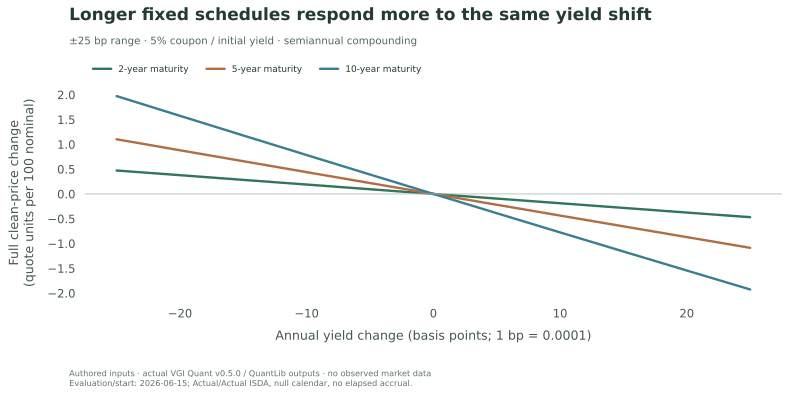

In [12]:
display(
    curve.loc[
        curve.shock_bp.isin([-YIELD_RANGE_BP, 0, YIELD_RANGE_BP]),
        [
            "years",
            "shock_bp",
            "full_price",
            "full_change",
            "duration_change",
            "second_order_change",
            "inverse_error_bp",
        ],
    ]
)
example.bond_changes(curve, YIELD_RANGE_BP)

### Compare residuals without presuming an improvement

Positive residuals overstate the full model price change; negative residuals understate it. Each panel shares the same quote-unit y scale. The table counts where the quadratic term improves absolute error; that outcome is measured, not required as an invariant.

In [13]:
%%sql summary <<
SELECT years,count(*) AS scenarios,max(abs(duration_error)) AS max_duration_error,
 max(abs(second_order_error)) AS max_second_order_error,
 count(*) FILTER(WHERE shock_bp<>0 AND abs(second_order_error)<abs(duration_error)) AS second_order_better,
 max(abs(inverse_error_bp)) AS max_inverse_error_bp FROM errors GROUP BY years ORDER BY years;

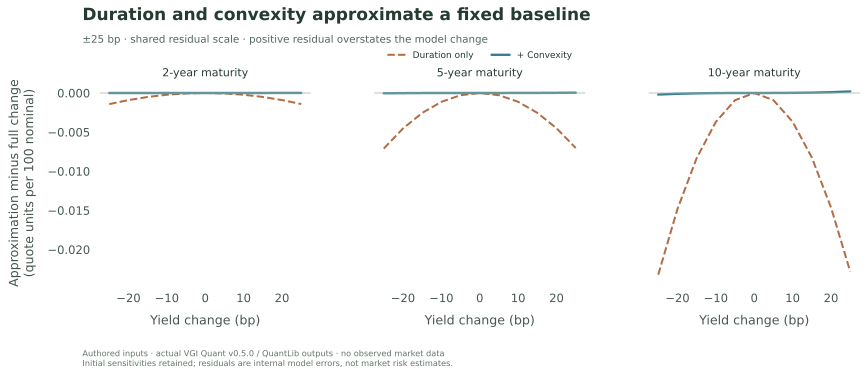

In [14]:
example.bond_errors(curve, YIELD_RANGE_BP)

In [15]:
display(summary)
prose(
    f"Across **{len(curve)} model scenarios**, the largest absolute duration-only residual is **{summary.max_duration_error.max():.6f} quote units**, versus **{summary.max_second_order_error.max():.6f}** with convexity. Maximum yield-inversion residual is **{summary.max_inverse_error_bp.max():.3g} basis points**. Wider shocks can expose omitted higher-order effects; these internal comparisons do not measure market risk accuracy."
)
export = Path("artifacts/data/02")
export.mkdir(parents=True, exist_ok=True)
curve.to_csv(export / "curve.csv", index=False)
baseline_frame.to_csv(export / "baseline.csv", index=False)
summary.to_csv(export / "summary.csv", index=False)

,years,scenarios,max_duration_error,max_second_order_error,second_order_better,max_inverse_error_bp
0,2,11,0.001421,0.000003,10,4.163336e-12
1,5,11,0.007100,0.000034,10,4.510281e-12
2,10,11,0.023214,0.000199,10,3.191891e-12


Across **33 model scenarios**, the largest absolute duration-only residual is **0.023214 quote units**, versus **0.000199** with convexity. Maximum yield-inversion residual is **4.51e-12 basis points**. Wider shocks can expose omitted higher-order effects; these internal comparisons do not measure market risk accuracy.

### Reconcile quotes, rows and inversion

The schedule is held fixed, prices remain positive, and increasing yield should reduce these fixed positive cash-flow prices. NULL inputs must remain NULL rather than becoming a par quote. Invalid inputs are not included in the scenario set.

In [16]:
%%sql checks <<
SELECT 'complete three-bond grid' AS check_name,(SELECT count(*)=3*(2*{{YIELD_RANGE_BP}}//5+1) FROM errors) AS passed
UNION ALL SELECT 'unique instrument/shock keys',(SELECT count(*)=count(DISTINCT(years,shock_bp)) FROM errors)
UNION ALL SELECT 'selected endpoints',(SELECT min(shock_bp)=-{{YIELD_RANGE_BP}} AND max(shock_bp)={{YIELD_RANGE_BP}} FROM errors)
UNION ALL SELECT 'positive finite outputs',(SELECT bool_and(isfinite(full_price) AND full_price>0 AND scenario_yield>0) FROM errors)
UNION ALL SELECT 'zero shock agrees',(SELECT max(abs(full_change))+max(abs(second_order_change))<1e-9 FROM errors WHERE shock_bp=0)
UNION ALL SELECT 'positive local sensitivity magnitudes',(SELECT bool_and(duration>0 AND convexity>0 AND duration<years) FROM baseline)
UNION ALL SELECT 'par quote near100',(SELECT max(abs(base_price-100))<0.01 FROM baseline)
UNION ALL SELECT 'inverted yield within0.001bp',(SELECT max(abs(inverse_error_bp))<0.001 FROM errors)
UNION ALL SELECT 'price declines as yield rises',(SELECT bool_and(prev IS NULL OR full_price<prev) FROM (SELECT *,lag(full_price) OVER(PARTITION BY years ORDER BY shock_bp) prev FROM errors))
UNION ALL SELECT 'NULL price staysNULL',quant.main.bond_price(NULL,0.05,0.05,10,2) IS NULL;

In [17]:
display(checks)
assert checks.passed.notna().all() and checks.passed.all()
prose(f"**{len(checks)} SQL checks passed**, plus the independent face-amount quote comparison.")

,check_name,passed
0,complete three-bond grid,True
1,unique instrument/shock keys,True
2,selected endpoints,True
3,positive finite outputs,True
4,zero shock agrees,True
5,positive local sensitivity magnitudes,True
6,par quote near100,True
7,inverted yield within0.001bp,True
8,price declines as yield rises,True
9,NULL price staysNULL,True


**10 SQL checks passed**, plus the independent face-amount quote comparison.

### Focused experiment: widen the yield range

Change only **`YIELD_RANGE_BP` from 25 to 200**. The three baseline instruments and their sensitivities remain fixed; spacing remains 5 bp, so existing grid points must reproduce exactly within floating-point tolerance. Compare maximum residuals and the maturity panels. This is instantaneous model repricing with one yield per instrument, not a yield-curve forecast, trading rule or holding-period return.

In [18]:
assert con.execute("SELECT * FROM duckdb_secrets()").fetchall() == []
session.close()

<a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Worker repository: vgi-quant](https://github.com/vgi-quant)
